# Laboratory 2

**Before you start:** 
1. Install foldseek using https://github.com/steineggerlab/foldseek
1. Install PyMol using https://github.com/schrodinger/pymol-open-source
1. Run `fetch_data.sh`

In [1]:
import collections
import pandas as pd
import matplotlib.pyplot as plt

## Helpers

In [2]:
def cluster_stats(tsv):
    """*_cluster.tsv is: representative <TAB> member"""
    n = collections.Counter(l.split("\t")[0] for l in open(tsv))
    s = list(n.values())
    return dict(
        clusters=len(n),
        avg_size=round(sum(s) / len(n), 2),
        singletons=sum(1 for x in s if x == 1),
        largest=max(s),
    )

## Structural alignment and clustering

Run `foldseek.sh`

### Analyze `search` and `cluster` results

In [3]:
foldseek_search = pd.read_csv(
    "work/fs_hits.tsv",
    sep="\t",
    names=["query", "target", "identity", "alntmscore", "evalue", "bits"],
)

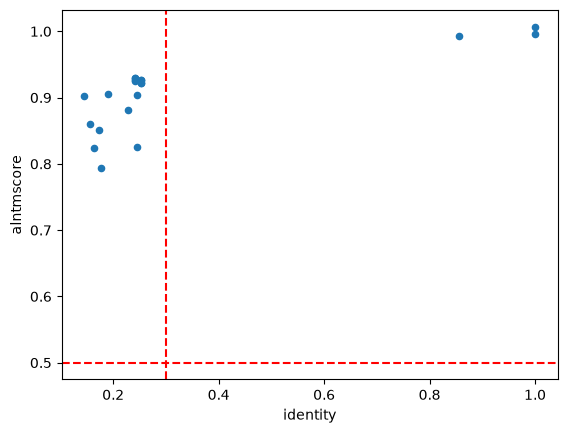

In [4]:
foldseek_search.plot(x="identity", y="alntmscore", kind="scatter")
plt.axvline(x=0.3, c="r", ls="--")
plt.axhline(y=0.5, c="r", ls="--");

### Analyze `cluster` results

In [5]:
cluster_stats("work/fsclu_cluster.tsv")

{'clusters': 16, 'avg_size': 1.69, 'singletons': 10, 'largest': 4}

In [6]:
clusters = pd.read_csv(
    "work/fsclu_cluster.tsv", sep="\t", header=None, names=["centroid", "member"]
)

In [7]:
clusters.groupby("centroid")[["member"]].agg("count").sort_values(
    "member", ascending=False
)

,member
centroid,
3HHB_B,4
3HHB_C,4
2MM1,3
1ITH_B,2
2GDM,2
2TRX_B,2
1CRN,1
1CG5_A,1
1UBQ,1


In [8]:
clusters.groupby("centroid")[["member"]].agg(list).loc["2TRX_B"].values

array([list(['2TRX_B', '2TRX_A'])], dtype=object)

Is this expected? What happens if we set `alignment-type = 1` and `tmscore-threshold = 0.8`?

---
# Exercise

## How does foldseek clustering compare againt mmseqs2?

- Transform query and target proteins into Foldseek database using `createdb`
- Transform query and target Foldseek databses into fasta files using `convert2fasta`
- Run MMseqs2 `easy-search` for the above fasta files with the same e-value and coverage parameters as in Foldseek
- List the globins Foldseek finds and MMseqs2 misses, with identity and TM-score. What is the highest sequence identity among them?
- What happens if we set `c = 0`?

Run `mmseqs.sh` (`createdb` → `convert2fasta` → MMseqs2 `easy-search`, with `-e 10 -c 0.8` and then `-c 0`)

In [9]:
def mmseqs_hits(c):
    return pd.read_csv(
        f"work/mm_hits_c{c}.tsv",
        sep="\t",
        names=["query", "target", "identity", "evalue", "bits"],
    )


def missed_by_mmseqs(c):
    mm = mmseqs_hits(c)
    return foldseek_search[~foldseek_search.target.isin(mm.target)].sort_values(
        "identity", ascending=False
    )


mmseqs_hits(0.8)

,query,target,identity,evalue,bits
0,1MBN,1MBN,1.000,1.213000e-101,312
1,1MBN,1MBO,1.000,1.213000e-101,312
2,1MBN,2MM1,0.861,1.407000e-89,277
3,1MBN,1CG5_A,0.244,1.367000e-08,43


In [10]:
missed = missed_by_mmseqs(0.8)
print(f"Foldseek: {len(foldseek_search)} hits, MMseqs2: {len(mmseqs_hits(0.8))}, missed: {len(missed)}")
print("Highest identity among missed:", missed.identity.max())
missed[["target", "identity", "alntmscore"]]

Foldseek: 20 hits, MMseqs2: 4, missed: 16
Highest identity among missed: 0.253


,target,identity,alntmscore
3,1A3N_A,0.253,0.9227
4,3HHB_A,0.253,0.9261
5,3HHB_C,0.253,0.9261
6,1A3N_C,0.253,0.9218
12,2LHB,0.246,0.8250
7,1A3N_B,0.241,0.9272
9,3HHB_B,0.241,0.9295
8,1A3N_D,0.241,0.9251
10,3HHB_D,0.241,0.9295
17,1ECD,0.229,0.8819


### What happens if we set `c = 0`?

In [11]:
missed0 = missed_by_mmseqs(0)
print("MMseqs2 hits:", len(mmseqs_hits(0)), "missed:", len(missed0))
print("Highest identity among missed:", missed0.identity.max())
mmseqs_hits(0)

MMseqs2 hits: 5 missed: 15
Highest identity among missed: 0.253


,query,target,identity,evalue,bits
0,1MBN,1MBN,1.000,1.213000e-101,312
1,1MBN,1MBO,1.000,1.213000e-101,312
2,1MBN,2MM1,0.861,1.407000e-89,277
3,1MBN,2LHB,0.283,8.754000e-10,46
4,1MBN,1CG5_A,0.244,1.367000e-08,43


**Answer:** the 16 missed globins (hemoglobin chains, leghemoglobin, etc.) share only 14–25% sequence identity with myoglobin (highest: 0.253, 1A3N/3HHB α chains) but have TM-score 0.79–0.93. With `c = 0` MMseqs2 only adds 2LHB (a short, noisy local alignment, e-value 9e-10); 15 globins are still missed, so lowering coverage doesn't recover them.

### Foldseek vs MMseqs2 hits: identity vs TM-score

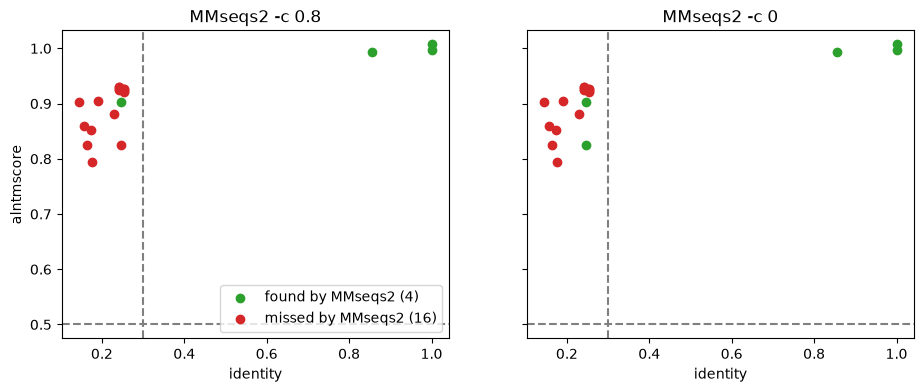

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, c in zip(axes, [0.8, 0]):
    found = foldseek_search.target.isin(mmseqs_hits(c).target)
    for flag, color, label in [(True, "tab:green", "found by MMseqs2"), (False, "tab:red", "missed by MMseqs2")]:
        d = foldseek_search[found == flag]
        ax.scatter(d.identity, d.alntmscore, c=color, label=f"{label} ({len(d)})")
    ax.axvline(x=0.3, c="gray", ls="--")
    ax.axhline(y=0.5, c="gray", ls="--")
    ax.set_title(f"MMseqs2 -c {c}")
    ax.set_xlabel("identity")
axes[0].set_ylabel("alntmscore")
axes[0].legend(loc="lower right");

### Foldseek vs MMseqs2 bit scores for the hits both tools found

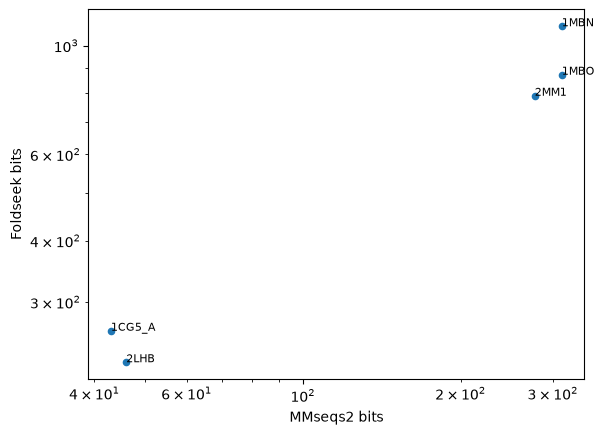

In [13]:
both = foldseek_search.merge(mmseqs_hits(0), on=["query", "target"], suffixes=("_fs", "_mm"))
ax = both.plot(x="bits_mm", y="bits_fs", kind="scatter", logx=True, logy=True)
for _, r in both.iterrows():
    ax.annotate(r.target, (r.bits_mm, r.bits_fs), fontsize=8)
ax.set_xlabel("MMseqs2 bits")
ax.set_ylabel("Foldseek bits");